In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


(256, 256)


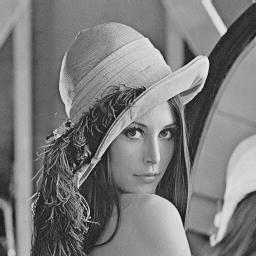

In [ ]:
img = cv2.imread('/content/gdrive/My Drive/ColabIP26/Images/lena256.jpg')
gimg = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
RGB_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print(gimg.shape)
cv2_imshow(gimg)

In [ ]:

gx = np.array([[-1, 0], [0, 1]], dtype=int)
gy = np.array([[0, -1], [1, 0]], dtype=int)

print(gx)
print(gy)

[[-1  0]
 [ 0  1]]
[[ 0 -1]
 [ 1  0]]


In [ ]:
x = cv2.filter2D(gimg, -1, gx)
y = cv2.filter2D(gimg, -1, gy)

In [ ]:
absX = cv2.convertScaleAbs(x)
absY = cv2.convertScaleAbs(y)

In [ ]:
#absX = absX * 3
#absY = absY * 3

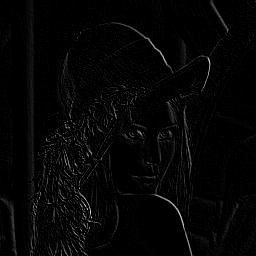

In [ ]:
#cv2_imshow(absX)
cv2_imshow(absY)

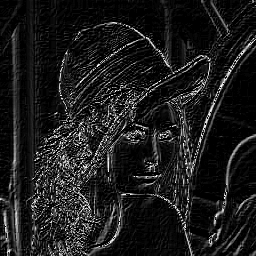

In [ ]:
outimg = cv2.addWeighted(absX, 0.5, absY, 0.5, 0)
outimg = outimg * 3
cv2_imshow(outimg)

In [ ]:
gBin = np.zeros(gimg.shape, dtype=np.uint8)

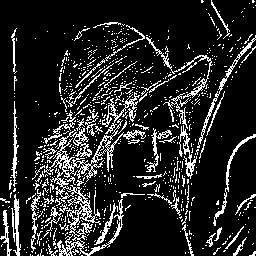

In [33]:
# 이미지 초기화
gBin = np.zeros(gimg.shape, dtype=np.uint8)

threshold = 60

for h in range(gimg.shape[0]):
    for w in range(gimg.shape[1]):
        if outimg[h, w] > threshold:
            gBin[h, w] = 255

cv2_imshow(gBin)

In [38]:
gx = np.array([[-1, 0, 1],
               [-2, 0, 2],
               [-1, 0, 1]], dtype=int)

gy = np.array([[-1, -2, -1],
               [ 0,  0,  0],
               [ 1,  2,  1]], dtype=int)


In [39]:
x = cv2.filter2D(gimg, -1, gx)
y = cv2.filter2D(gimg, -1, gy)

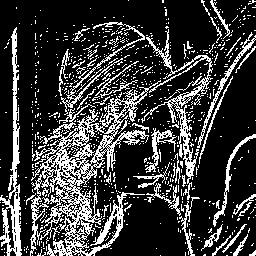

In [40]:
gBin = np.zeros(gimg.shape, dtype=np.uint8)

threshold = 40

for h in range(gimg.shape[0]):
    for w in range(gimg.shape[1]):
        if outimg[h, w] > threshold:
            gBin[h, w] = 255

cv2_imshow(gBin)

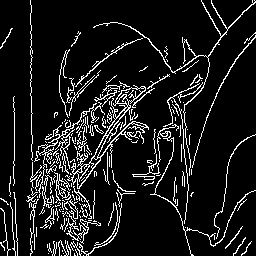

In [42]:
cannyimg = cv2.Canny(gimg, 100, 200)
cv2_imshow(cannyimg)

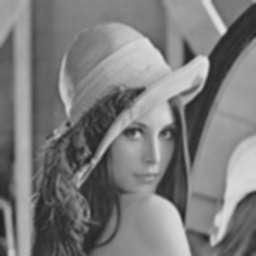

In [44]:
blurimg = cv2.GaussianBlur(gimg, (5, 5), 1.4)
cv2_imshow(blurimg)

In [45]:
x = cv2.filter2D(blurimg, -1, gx)
y = cv2.filter2D(blurimg, -1, gy)

In [46]:
x = cv2.convertScaleAbs(x)
y = cv2.convertScaleAbs(y)

In [50]:
edgeDirection = np.arctan2(y, x)

print(edgeDirection)
print(edgeDirection.shape)

[[0.     0.     0.     ... 0.     0.     0.    ]
 [0.     0.     0.     ... 0.     0.     0.    ]
 [0.     0.     0.     ... 0.     0.     0.    ]
 ...
 [0.     0.     0.     ... 0.8804 1.107  1.57  ]
 [0.     0.     0.     ... 0.611  0.8623 1.57  ]
 [0.     0.     0.     ... 0.     0.     0.    ]]
(256, 256)


In [52]:
angle = np.rad2deg(edgeDirection)
print(angle)

[[ 0.    0.    0.   ...  0.    0.    0.  ]
 [ 0.    0.    0.   ...  0.    0.    0.  ]
 [ 0.    0.    0.   ...  0.    0.    0.  ]
 ...
 [ 0.    0.    0.   ... 50.44 63.44 90.  ]
 [ 0.    0.    0.   ... 35.   49.4  90.  ]
 [ 0.    0.    0.   ...  0.    0.    0.  ]]
